# 🌦️ Lanka HeatCast — Ensemble Learning for Next-Day Temperature Forecasting in Sri Lanka

**Module hands-on project · Ensemble Learning (Bagging · Boosting · Stacking) + Hybrid models**
**Author:** Ravindu Dilshan

### The story
Sri Lanka packs three very different climates into one small island: the hot, humid **coastal lowlands (Colombo, 9 m)**,
the **mid-country hills (Kandy, ~500 m)** and the cool **central highlands (Nuwara Eliya, ~1,900 m)**.
The Department of Meteorology issues *heat-index advisories* when daytime temperatures climb, and farmers, schools,
outdoor workers and the power grid (air-conditioning load) all care about **how hot tomorrow will be**.

**Goal:** predict **tomorrow's maximum temperature (°C)** for each city from today's and recent weather, and find out
*which ensemble strategy works best and why*.

### Dataset (Sri Lankan, real)
* Source: **Open-Meteo Historical Weather API** (ERA5 / ERA5-Land reanalysis), queried at the coordinates of Colombo, Kandy and Nuwara Eliya.
* Period: **1 Jan 2016 → 15 Nov 2026**, daily, **3 cities × 3,972 days = 11,916 rows**, 9 weather variables.
* Licence: CC BY 4.0 — *Weather data by Open-Meteo.com*.

### What this notebook covers
1. Data loading & quality checks → 2. EDA (climate zones, monsoons) → 3. Feature engineering (lags, rolling windows, monsoon season)
4. Baselines → 5. **Bagging** (Bagged Trees, Random Forest, Extra Trees) → 6. **Boosting** (AdaBoost, Gradient Boosting, LightGBM, CatBoost)
7. ANN (MLP) → 8. **Stacking** (RF + LightGBM + CatBoost + ANN → Ridge meta-learner)
9. **Hybrids**: ARIMA + Random Forest (Zhang-style residual hybrid) and RF + ANN blend
10. Comparison, per-city analysis, feature importance, and **interpretation of why models behave as they do**
11. Export of artefacts for the Streamlit dashboard.

>

In [1]:
import warnings, json, os, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.ensemble import (BaggingRegressor, RandomForestRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import lightgbm as lgb
from catboost import CatBoostRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL
import joblib

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
CITY_COLORS = {'Colombo': '#1f77b4', 'Kandy': '#2ca02c', 'Nuwara Eliya': '#9467bd'}
os.makedirs('artifacts', exist_ok=True)
print('Libraries loaded. LightGBM', lgb.__version__)

Libraries loaded. LightGBM 4.7.0


## 1. Load the Sri Lankan weather data

In [2]:
DATA = 'data/sri_lanka_weather_2016_2026.csv'
CITIES = {'Colombo': (6.9271, 79.8612), 'Kandy': (7.2906, 80.6337), 'Nuwara Eliya': (6.9497, 80.7891)}
VARS = ['temperature_2m_mean','temperature_2m_max','temperature_2m_min','precipitation_sum',
        'relative_humidity_2m_mean','wind_speed_10m_max','shortwave_radiation_sum',
        'surface_pressure_mean','cloud_cover_mean']

def download_open_meteo(path=DATA, start='2016-01-01', end='2026-11-15'):
    # Re-creates the CSV from the free Open-Meteo archive API (no key needed).
    import requests
    frames = []
    for city, (lat, lon) in CITIES.items():
        r = requests.get('https://archive-api.open-meteo.com/v1/archive', params=dict(
            latitude=lat, longitude=lon, start_date=start, end_date=end,
            daily=','.join(VARS), timezone='Asia/Colombo'), timeout=60).json()
        f = pd.DataFrame(r['daily']).rename(columns={'time': 'date'})
        f.insert(0, 'city', city); f.insert(1, 'latitude', lat); f.insert(2, 'longitude', lon); f.insert(3, 'elevation', r['elevation'])
        frames.append(f); time.sleep(20)   # respect the free-tier rate limit
    os.makedirs(os.path.dirname(path), exist_ok=True)
    pd.concat(frames).to_csv(path, index=False)

if not os.path.exists(DATA):
    download_open_meteo()

df = pd.read_csv(DATA, parse_dates=['date']).sort_values(['city', 'date']).reset_index(drop=True)
print(df.shape)
df.head()

(11916, 14)


,city,latitude,longitude,elevation,date,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,relative_humidity_2m_mean,wind_speed_10m_max,shortwave_radiation_sum,surface_pressure_mean,cloud_cover_mean
0,Colombo,6.9271,79.8612,9,2016-01-01,26.9,30.1,24.6,0.1,78,16.9,17.72,1012.1,17
1,Colombo,6.9271,79.8612,9,2016-01-02,26.4,30.3,24.3,1.2,81,16.1,17.56,1013.1,36
2,Colombo,6.9271,79.8612,9,2016-01-03,27.0,31.1,24.1,0.0,76,20.6,19.97,1012.1,28
3,Colombo,6.9271,79.8612,9,2016-01-04,27.4,31.4,24.5,0.0,77,15.9,19.43,1011.9,51
4,Colombo,6.9271,79.8612,9,2016-01-05,26.9,30.6,24.2,0.3,80,13.2,18.85,1011.5,59


In [3]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else 'none')
print('\nDate range:', df.date.min().date(), '→', df.date.max().date())
print('Rows per city:', df.city.value_counts().to_dict())
print('Duplicate (city,date) rows:', df.duplicated(['city','date']).sum())
df.groupby('city')[VARS].mean().round(1).T

Missing values per column:
none

Date range: 2016-01-01 → 2026-11-15
Rows per city: {'Colombo': 3972, 'Kandy': 3972, 'Nuwara Eliya': 3972}
Duplicate (city,date) rows: 0


city,Colombo,Kandy,Nuwara Eliya
temperature_2m_mean,26.7,24.1,16.0
temperature_2m_max,29.7,28.3,19.9
temperature_2m_min,24.3,20.9,13.1
precipitation_sum,7.7,4.9,5.2
relative_humidity_2m_mean,83.1,81.3,85.8
wind_speed_10m_max,16.7,15.9,14.1
shortwave_radiation_sum,18.7,18.9,19.0
surface_pressure_mean,1008.9,955.2,815.5
cloud_cover_mean,74.4,74.5,82.1


## 2. Exploratory data analysis
Three cities, three climates. Elevation alone shifts temperature by ~**12 °C** between Colombo and Nuwara Eliya
(the environmental lapse rate is ≈6.5 °C per km). Rainfall is driven by the **South-West monsoon (May–Sep)**, which
soaks Colombo and the western slopes, and the **North-East monsoon (Dec–Feb)**, plus two *inter-monsoon* periods
(Mar–Apr, Oct–Nov) that bring convective thunderstorms.

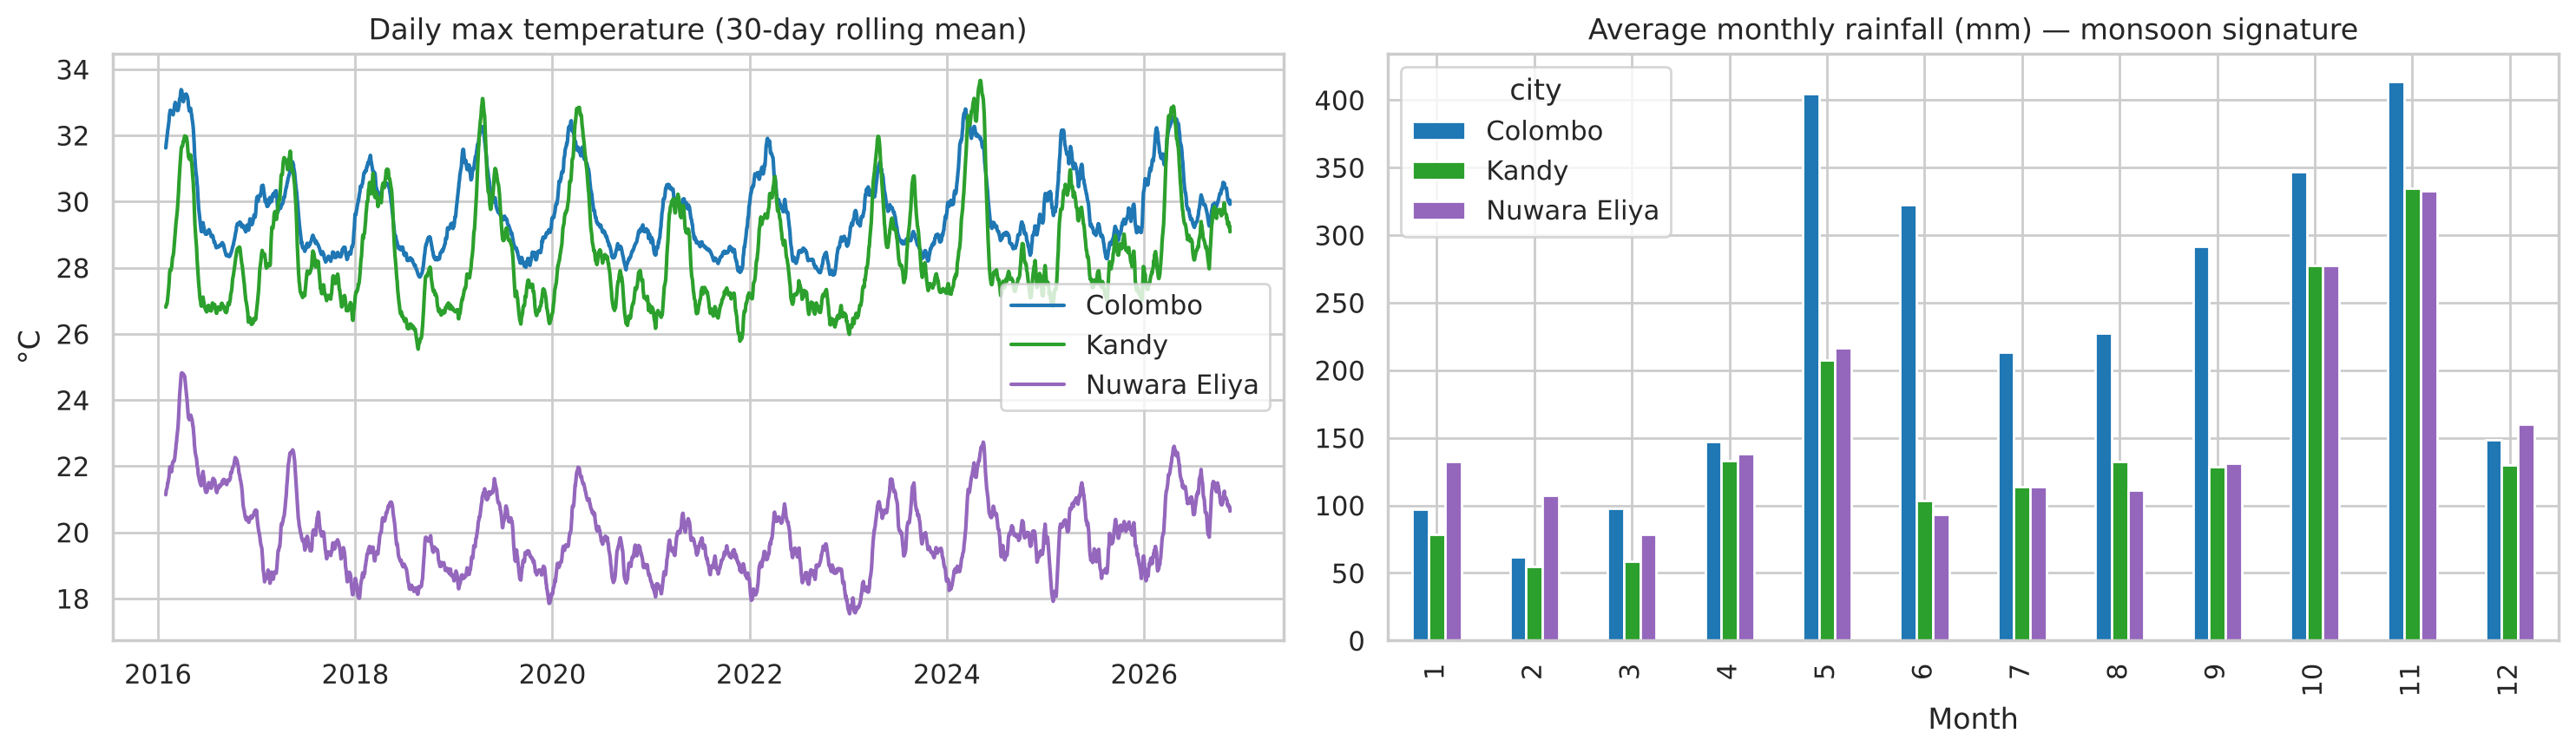

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for c, g in df.groupby('city'):
    m = g.set_index('date')['temperature_2m_max'].rolling(30).mean()
    axes[0].plot(m.index, m, label=c, color=CITY_COLORS[c])
axes[0].set_title('Daily max temperature (30-day rolling mean)'); axes[0].set_ylabel('°C'); axes[0].legend()
mon = df.assign(month=df.date.dt.month).groupby(['city','month'])['precipitation_sum'].mean().unstack(0) * 30
mon.plot(kind='bar', ax=axes[1], color=[CITY_COLORS[c] for c in mon.columns])
axes[1].set_title('Average monthly rainfall (mm) — monsoon signature'); axes[1].set_xlabel('Month')
plt.tight_layout(); plt.show()

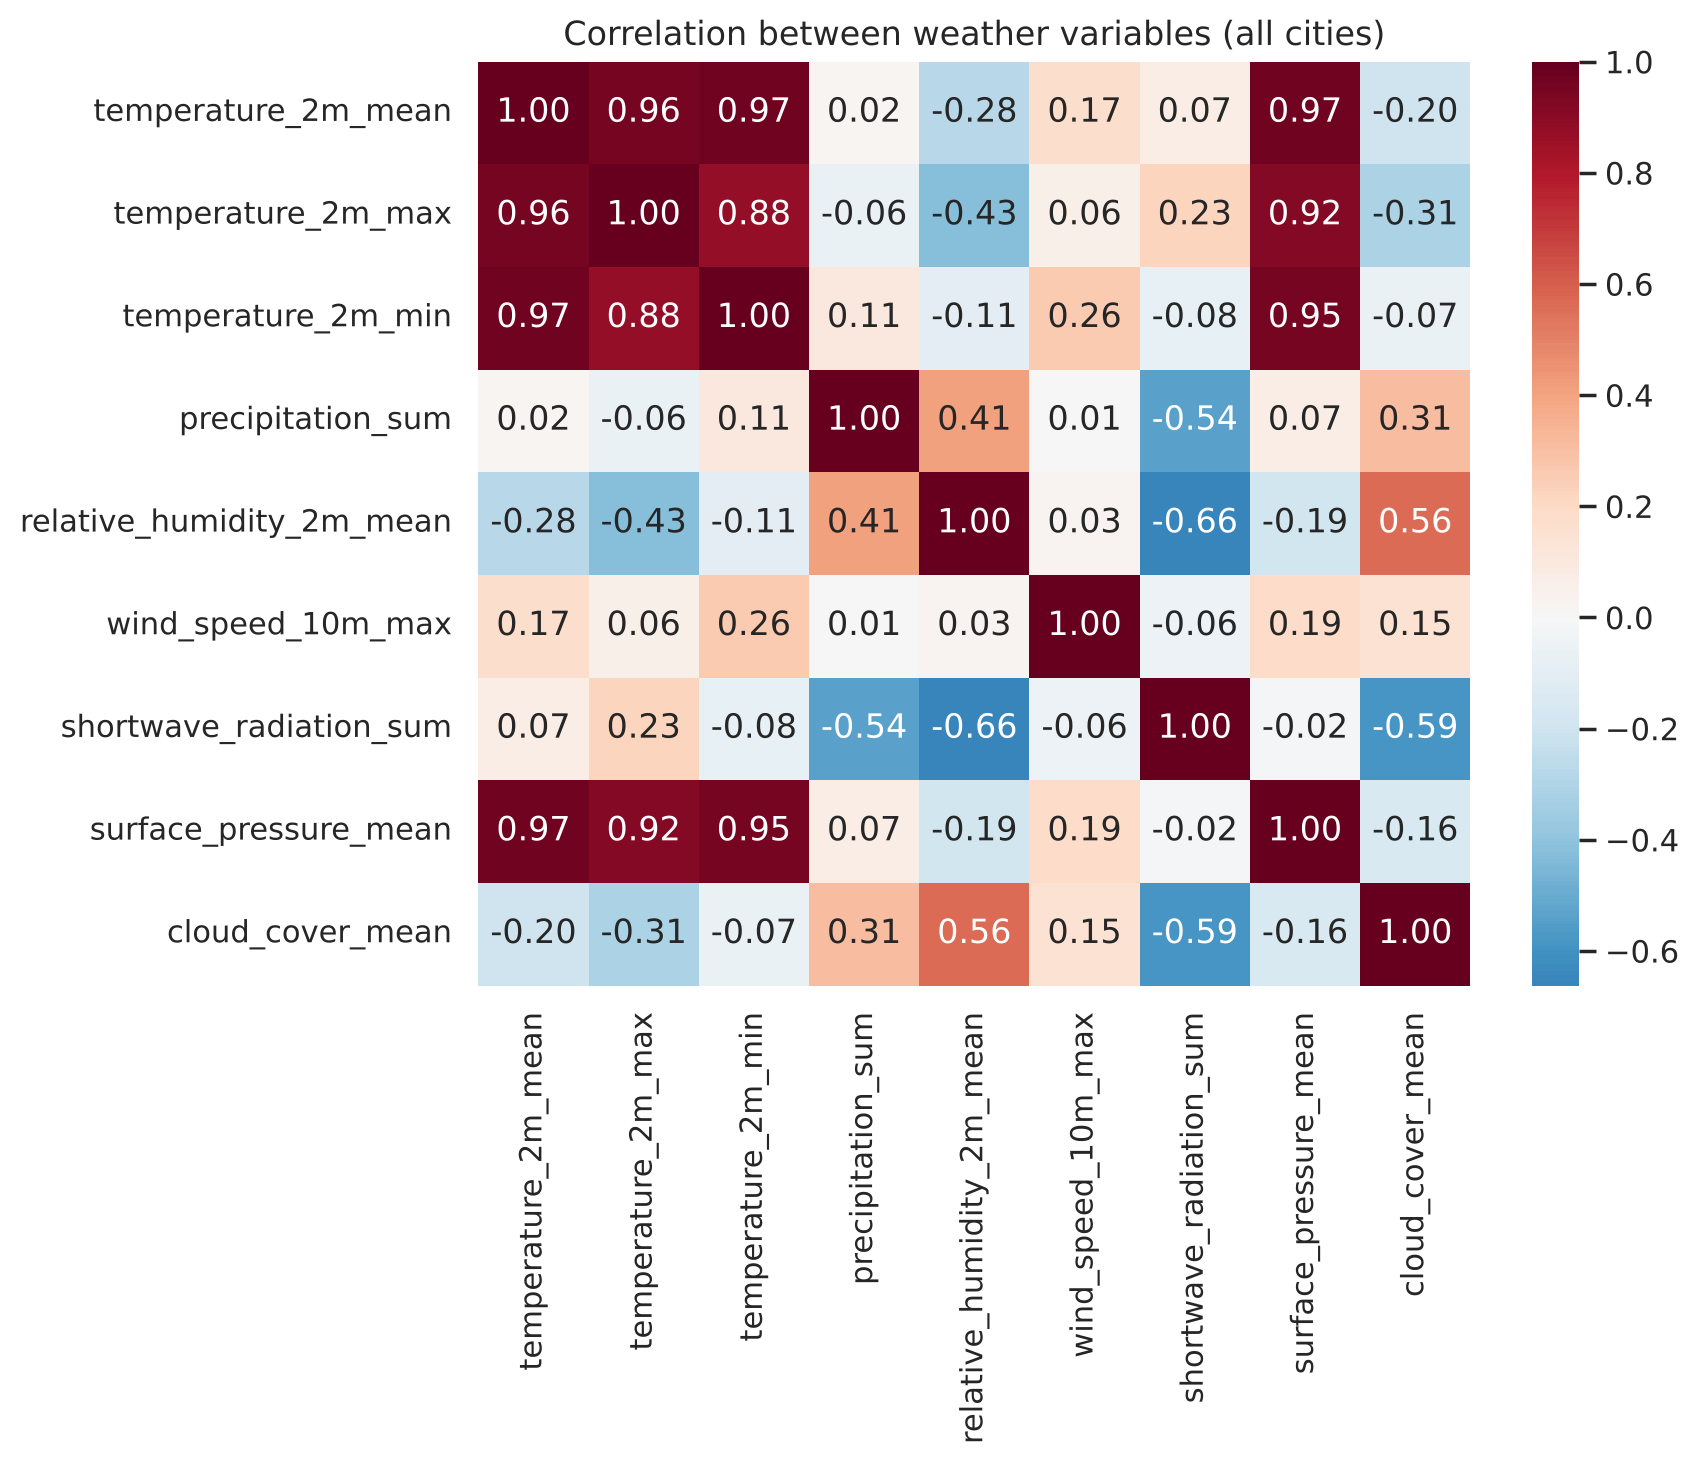

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df[VARS].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlation between weather variables (all cities)'); plt.show()

**What the EDA tells us**
* Temperature is strongly *persistent* (tomorrow ≈ today) and seasonal → lag features matter most.
* Max temperature is **negatively correlated with cloud cover, humidity and rainfall** and positively with solar radiation:
  a cloudy, rainy day caps the afternoon high. These are the non-linear "weather regime" effects tree ensembles can learn.
* A seasonal decomposition (below) shows a clear annual cycle plus a noisy residual — that residual is what the models compete on.

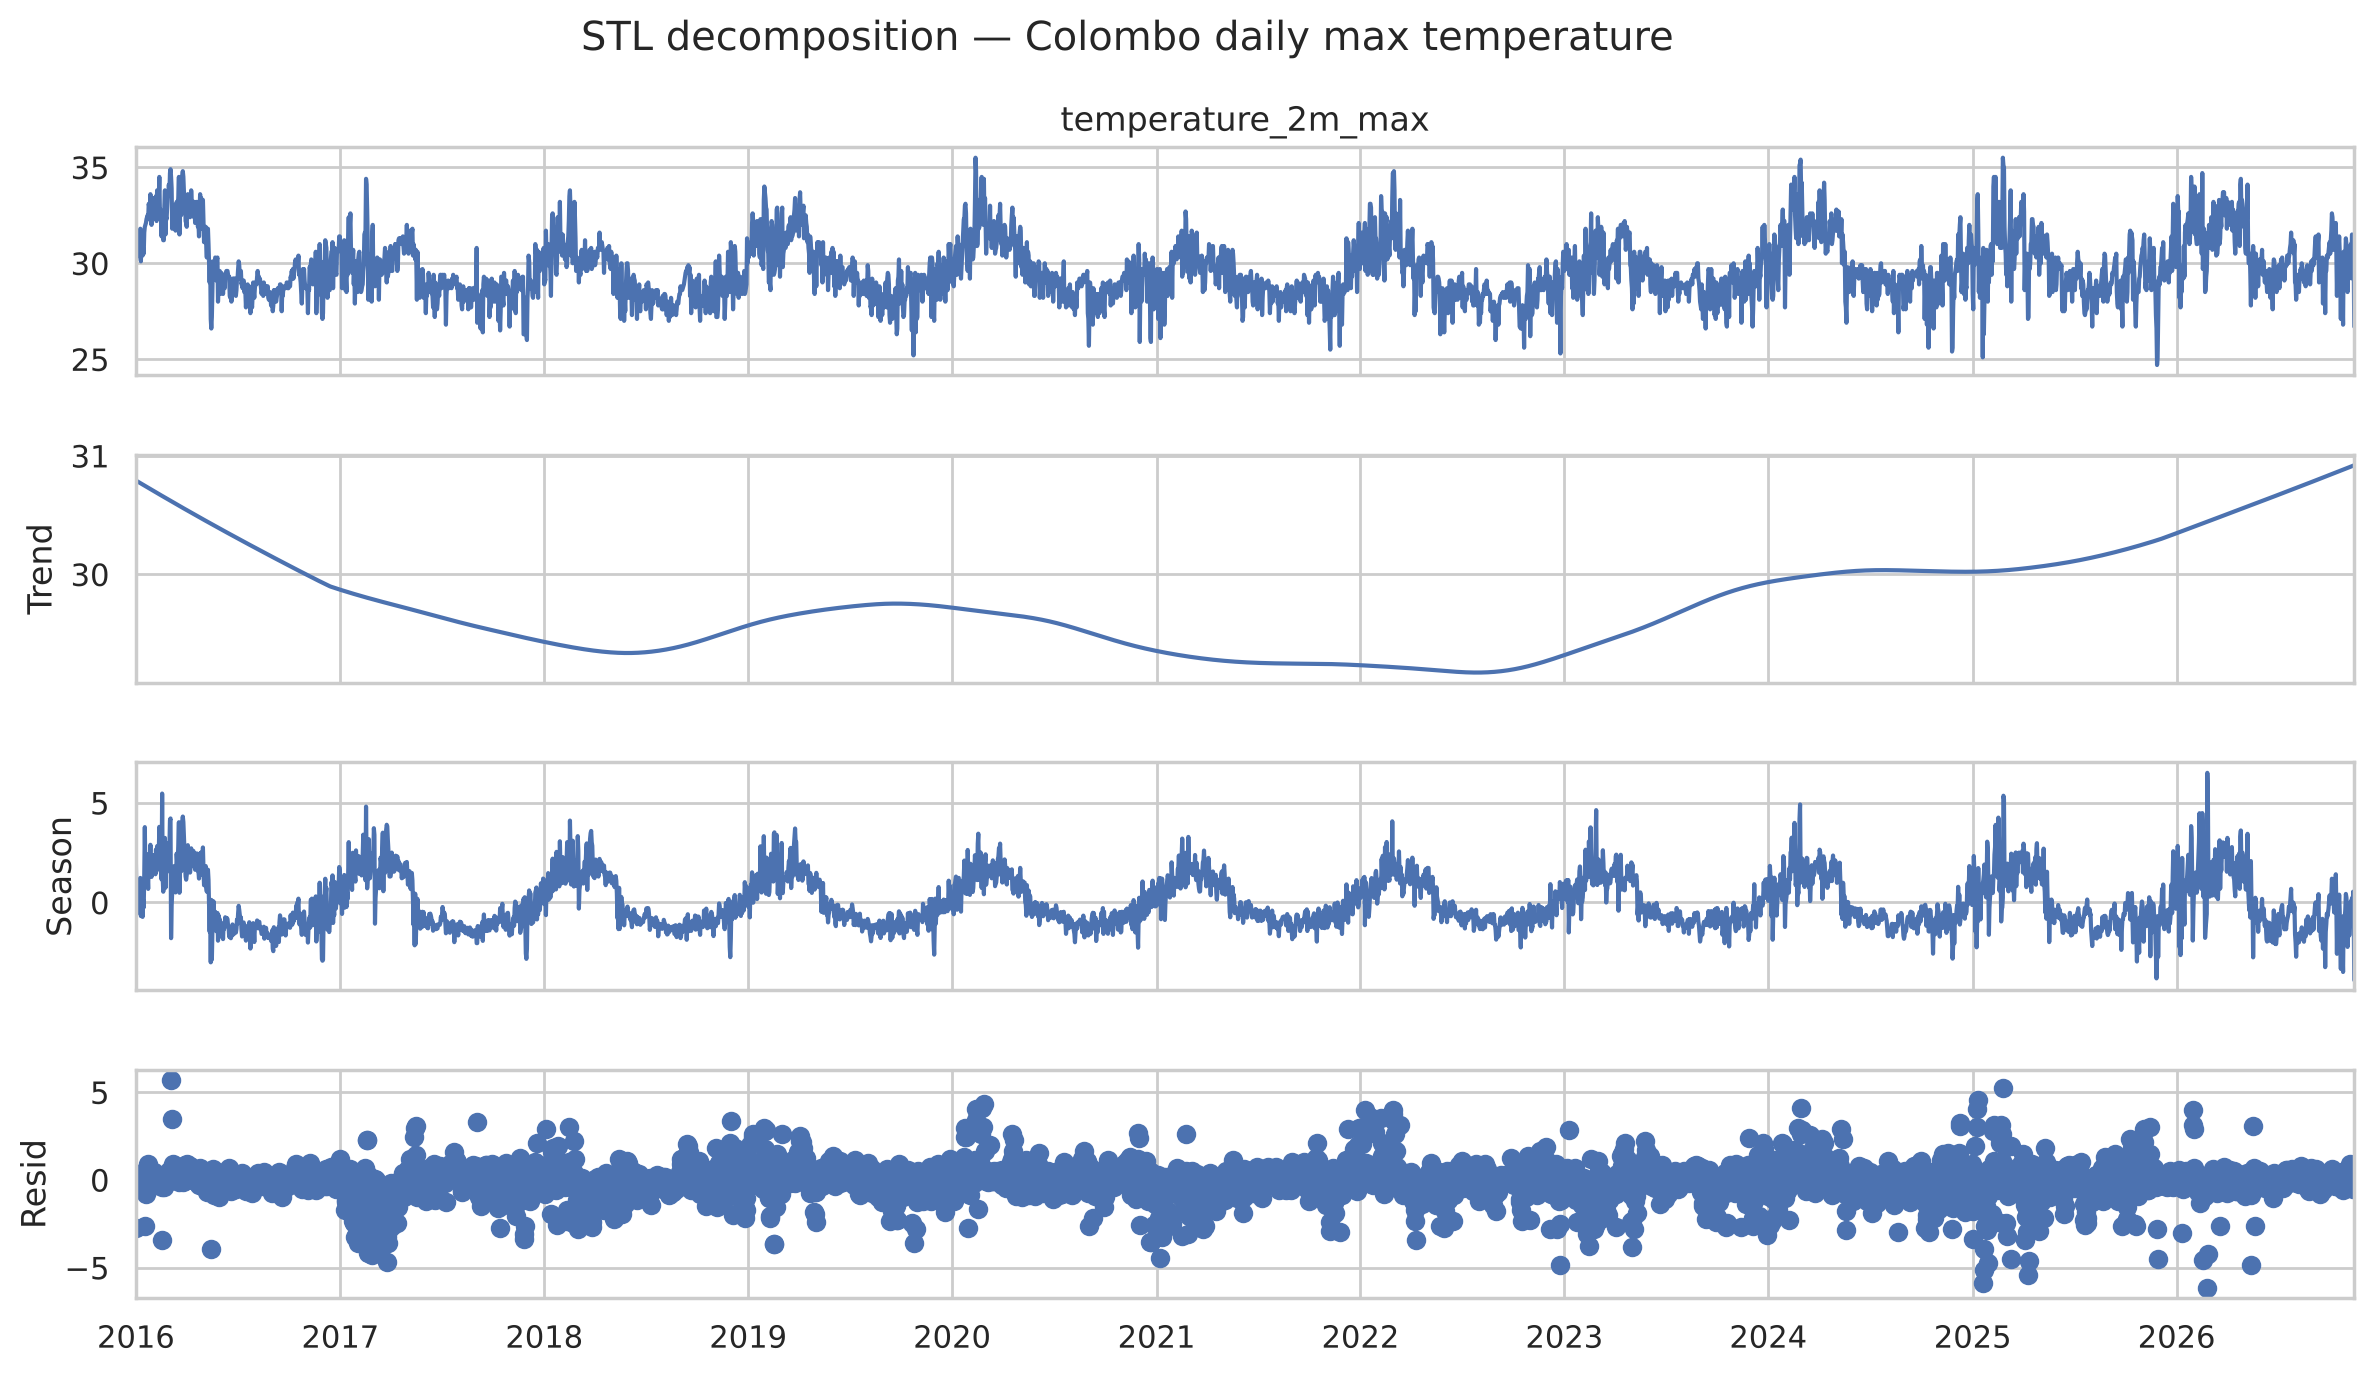

In [6]:
s = df[df.city=='Colombo'].set_index('date')['temperature_2m_max'].asfreq('D').interpolate()
res = STL(s, period=365, robust=True).fit()
fig = res.plot(); fig.set_size_inches(13, 7); fig.suptitle('STL decomposition — Colombo daily max temperature', y=1.01); plt.show()

## 3. Feature engineering
For each city and day *t* we predict **`target = temperature_2m_max(t+1)`** using only information available at the end of day *t*
(no leakage):
* **Lags** (t, t-1, t-2, t-6) of temperature, rain, humidity, cloud, radiation, wind, pressure
* **Rolling windows** (3-, 7-, 30-day means; 7-day rain total; 7-day temp std) → recent regime
* **Day-to-day changes** (Δ pressure, Δ temperature) → approaching weather systems
* **Calendar & climate**: sin/cos of day-of-year, month, **monsoon season**, city one-hot + elevation

In [7]:
def monsoon(m):
    return {12:'NE monsoon',1:'NE monsoon',2:'NE monsoon',3:'1st inter-monsoon',4:'1st inter-monsoon',
            5:'SW monsoon',6:'SW monsoon',7:'SW monsoon',8:'SW monsoon',9:'SW monsoon',
            10:'2nd inter-monsoon',11:'2nd inter-monsoon'}[m]

def make_features(d):
    out = []
    for city, g in d.groupby('city'):
        g = g.sort_values('date').copy()
        short = {'temperature_2m_max':'tmax','temperature_2m_mean':'tmean','temperature_2m_min':'tmin',
                 'precipitation_sum':'rain','relative_humidity_2m_mean':'rh','cloud_cover_mean':'cloud',
                 'shortwave_radiation_sum':'rad','wind_speed_10m_max':'wind','surface_pressure_mean':'pres'}
        for v, s in short.items():
            g[f'{s}_lag0'] = g[v]
            for L in (1, 2, 6):
                g[f'{s}_lag{L}'] = g[v].shift(L)
        for w in (3, 7, 30):
            g[f'tmax_roll{w}'] = g['temperature_2m_max'].rolling(w).mean()
        g['tmax_std7'] = g['temperature_2m_max'].rolling(7).std()
        g['rain_sum7'] = g['precipitation_sum'].rolling(7).sum()
        g['rh_roll7'] = g['relative_humidity_2m_mean'].rolling(7).mean()
        g['cloud_roll3'] = g['cloud_cover_mean'].rolling(3).mean()
        g['pres_change'] = g['surface_pressure_mean'].diff()
        g['tmax_change'] = g['temperature_2m_max'].diff()
        g['dtr'] = g['temperature_2m_max'] - g['temperature_2m_min']        # diurnal temperature range
        g['target'] = g['temperature_2m_max'].shift(-1)                     # tomorrow's max temp
        out.append(g)
    f = pd.concat(out)
    doy = f.date.dt.dayofyear
    f['doy_sin'], f['doy_cos'] = np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25)
    f['month'] = f.date.dt.month
    f['season'] = f.month.map(monsoon)
    f = pd.get_dummies(f, columns=['season'], prefix='ssn', dtype=int)
    f = pd.get_dummies(f.assign(city_=f.city), columns=['city_'], prefix='city', dtype=int)
    return f.dropna().reset_index(drop=True)

feat = make_features(df)
FEATURES = [c for c in feat.columns if c not in VARS + ['city','date','latitude','longitude','target']]
print(len(FEATURES), 'features,', len(feat), 'rows')
FEATURES[:12]

57 features, 11826 rows


['elevation',
 'tmax_lag0',
 'tmax_lag1',
 'tmax_lag2',
 'tmax_lag6',
 'tmean_lag0',
 'tmean_lag1',
 'tmean_lag2',
 'tmean_lag6',
 'tmin_lag0',
 'tmin_lag1',
 'tmin_lag2']

### Chronological train / test split
Weather is a time series, so we **never shuffle**. Train on **2016–2023**, test on **1 Jan 2024 → 14 Nov 2026**
(≈ 2.9 years the models have never seen, including the 2024 heat-wave period and two full monsoon cycles).

In [8]:
SPLIT = pd.Timestamp('2024-01-01')
train, test = feat[feat.date < SPLIT], feat[feat.date >= SPLIT]
Xtr, ytr, Xte, yte = train[FEATURES], train['target'], test[FEATURES], test['target']
# Models learn the CHANGE from today's max temperature (tomorrow − today), then we add today's value back.
# Tree ensembles cannot extrapolate beyond the target range seen in training; predicting the day-to-day change
# keeps the target stationary and lets them track a warming climate (see interpretation section).
ytr_d = ytr - Xtr['tmax_lag0']
print(f'Train: {len(train):,} rows ({train.date.min().date()} → {train.date.max().date()})')
print(f'Test : {len(test):,} rows ({test.date.min().date()} → {test.date.max().date()})')

RESULTS, PREDS, FIT_TIME = {}, {}, {}
def evaluate(name, pred, family, fit_seconds=np.nan):
    pred = np.asarray(pred)
    PREDS[name] = pred
    RESULTS[name] = dict(family=family, MAE=mean_absolute_error(yte, pred),
                         RMSE=mean_squared_error(yte, pred) ** 0.5, R2=r2_score(yte, pred),
                         fit_s=fit_seconds)
    print(f'{name:<28} MAE={RESULTS[name]["MAE"]:.3f} °C  RMSE={RESULTS[name]["RMSE"]:.3f}  R²={RESULTS[name]["R2"]:.3f}')

def fit_eval(name, model, family, X1=None, X2=None):
    X1 = Xtr if X1 is None else X1; X2 = Xte if X2 is None else X2
    t = time.time(); model.fit(X1, ytr_d); s = time.time() - t
    evaluate(name, model.predict(X2) + X2['tmax_lag0'].values, family, s)
    return model

Train: 8,679 rows (2016-01-30 → 2023-12-31)
Test : 3,147 rows (2024-01-01 → 2026-11-14)


## 4. Baselines — the bar every model must clear
* **Persistence**: tomorrow's max = today's max (very hard to beat for temperature!)
* **Climatology**: average max temperature for that city & day-of-year in the training years
* **Linear regression** and a **single decision tree** (the "weak learner" the ensembles are built from)

In [9]:
evaluate('Persistence (baseline)', test['tmax_lag0'], 'Baseline')
clim = train.assign(doy=train.date.dt.dayofyear).groupby(['city', 'doy'])['target'].mean()
clim_pred = [clim.get((c, d), np.nan) for c, d in zip(test.city, (test.date + pd.Timedelta(days=1)).dt.dayofyear)]
evaluate('Climatology (baseline)', pd.Series(clim_pred).fillna(ytr.mean()), 'Baseline')
models = {}
models['Linear Regression'] = fit_eval('Linear Regression', make_pipeline(StandardScaler(), LinearRegression()), 'Baseline')
models['Decision Tree'] = fit_eval('Decision Tree', DecisionTreeRegressor(max_depth=None, min_samples_leaf=5, random_state=SEED), 'Single model')

Persistence (baseline)       MAE=0.924 °C  RMSE=1.250  R²=0.932
Climatology (baseline)       MAE=1.311 °C  RMSE=1.662  R²=0.881
Linear Regression            MAE=0.834 °C  RMSE=1.100  R²=0.948


Decision Tree                MAE=1.081 °C  RMSE=1.409  R²=0.914


## 5. Bagging (Bootstrap Aggregating) — *reduce variance*
Bagging trains many deep trees on **bootstrap resamples** and averages them. A single deep tree over-fits (high variance);
averaging hundreds of de-correlated trees cancels much of that noise.
* **Bagged Trees** – plain bagging of decision trees
* **Random Forest** – bagging + random feature subsets at each split (further de-correlation)
* **Extra Trees** – random forests with *random split thresholds* (even more randomness, even lower variance)

In [10]:
models['Bagged Trees'] = fit_eval('Bagged Trees', BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=150, n_jobs=-1, random_state=SEED), 'Bagging')
models['Random Forest'] = fit_eval('Random Forest', RandomForestRegressor(n_estimators=400, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=SEED), 'Bagging')
models['Extra Trees'] = fit_eval('Extra Trees', ExtraTreesRegressor(n_estimators=400, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED), 'Bagging')

Bagged Trees                 MAE=0.859 °C  RMSE=1.132  R²=0.945


Random Forest                MAE=0.859 °C  RMSE=1.132  R²=0.945


Extra Trees                  MAE=0.857 °C  RMSE=1.132  R²=0.945


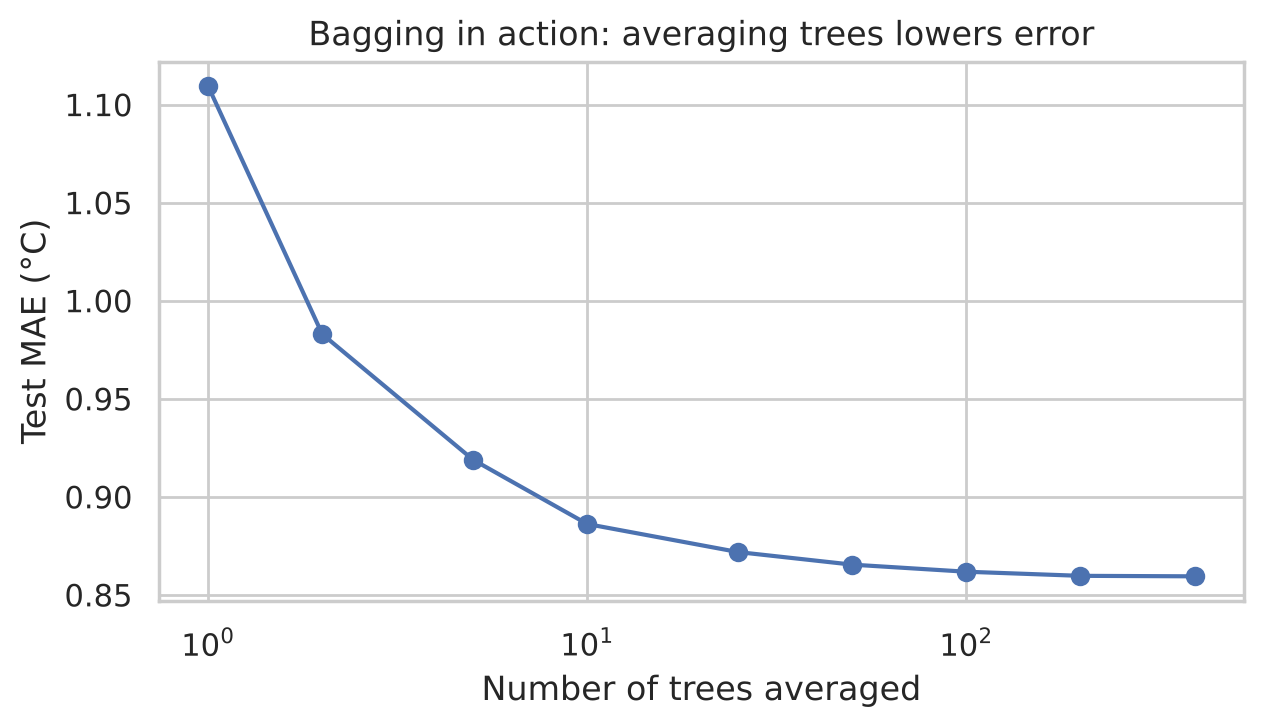

In [11]:
# How bagging reduces error as trees are added (Random Forest, test MAE vs number of trees)
rf = models['Random Forest']
tree_preds = np.stack([t.predict(Xte.values) for t in rf.estimators_]) + Xte['tmax_lag0'].values
ks = [1, 2, 5, 10, 25, 50, 100, 200, 400]
curve = [mean_absolute_error(yte, tree_preds[:k].mean(0)) for k in ks]
plt.figure(figsize=(7, 3.5)); plt.plot(ks, curve, 'o-'); plt.xscale('log')
plt.xlabel('Number of trees averaged'); plt.ylabel('Test MAE (°C)'); plt.title('Bagging in action: averaging trees lowers error'); plt.show()

## 6. Boosting — *reduce bias*
Boosting builds shallow trees **sequentially**, each one fitting the errors (gradients) of the ensemble so far.
* **AdaBoost** – re-weights hard examples
* **Gradient Boosting** (scikit-learn) – classic gradient boosting
* **LightGBM** – histogram-based, leaf-wise growth, very fast
* **CatBoost** – ordered boosting with symmetric (oblivious) trees, strong regularisation

In [12]:
models['AdaBoost'] = fit_eval('AdaBoost', AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), n_estimators=300, learning_rate=0.05, random_state=SEED), 'Boosting')
models['Gradient Boosting'] = fit_eval('Gradient Boosting', GradientBoostingRegressor(n_estimators=500, learning_rate=0.03, max_depth=4, subsample=0.8, random_state=SEED), 'Boosting')
models['LightGBM'] = fit_eval('LightGBM', lgb.LGBMRegressor(n_estimators=800, learning_rate=0.02, num_leaves=31, min_child_samples=30,
                                                         subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0, random_state=SEED, verbose=-1), 'Boosting')
models['CatBoost'] = fit_eval('CatBoost', CatBoostRegressor(iterations=1200, learning_rate=0.03, depth=6, l2_leaf_reg=3, random_seed=SEED, verbose=0), 'Boosting')

AdaBoost                     MAE=0.885 °C  RMSE=1.164  R²=0.941


Gradient Boosting            MAE=0.852 °C  RMSE=1.118  R²=0.946


LightGBM                     MAE=0.859 °C  RMSE=1.122  R²=0.946


CatBoost                     MAE=0.854 °C  RMSE=1.117  R²=0.946


## 7. Artificial Neural Network (MLP)
A feed-forward ANN (2 hidden layers) on standardised features. Neural nets learn smooth functions, which complements the
step-like functions of trees — a useful *diverse* member for stacking.

In [13]:
models['ANN (MLP)'] = fit_eval('ANN (MLP)', make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2, learning_rate_init=1e-3,
                                   max_iter=600, early_stopping=True, validation_fraction=0.15, random_state=SEED)), 'Neural network')

ANN (MLP)                    MAE=0.874 °C  RMSE=1.135  R²=0.944


## 8. Stacking — *learn how to combine*
Stacking feeds the predictions of diverse **base learners** (Linear Regression, Random Forest = bagging, LightGBM & CatBoost = boosting,
MLP = neural net) into a **meta-learner** (non-negative linear regression) that learns the best weighting.

To avoid leakage we build the meta-features with **time-ordered out-of-fold predictions** (`TimeSeriesSplit`, 5 folds):
each training row's meta-feature is predicted by base models trained only on *earlier* data.

In [14]:
from sklearn.base import clone
BASE = {k: models[k] for k in ['Linear Regression', 'Random Forest', 'LightGBM', 'CatBoost', 'ANN (MLP)']}
tss = TimeSeriesSplit(n_splits=5)
oof = pd.DataFrame(np.nan, index=Xtr.index, columns=list(BASE))
t0 = time.time()
for fold, (a, b) in enumerate(tss.split(Xtr)):
    for name, m in BASE.items():
        mm = clone(m).fit(Xtr.iloc[a], ytr_d.iloc[a])
        oof.iloc[b, oof.columns.get_loc(name)] = mm.predict(Xtr.iloc[b]) + Xtr['tmax_lag0'].iloc[b].values
# Use meta-features only from folds 3-5, where base models were trained on >= ~4 years of data
# (fold-1/2 models see too little history, their predictions are biased and would mislead the meta-learner).
fold_starts = [b[0] for _, b in tss.split(Xtr)]
mask = oof.notna().all(1) & (np.arange(len(Xtr)) >= fold_starts[2])
# Non-negative linear meta-learner: base predictions are highly correlated, so unconstrained weights
# explode (e.g. +3.5 / −3.3). Constraining weights ≥ 0 gives a stable, interpretable convex-like combination.
meta = LinearRegression(positive=True).fit(oof[mask], ytr[mask])
test_meta = pd.DataFrame({n: PREDS[n] for n in BASE}, index=Xte.index)
evaluate('Stacking (meta-learner)', meta.predict(test_meta), 'Stacking', time.time() - t0)
weights = pd.Series(meta.coef_, index=list(BASE)).round(3)
print('\nMeta-learner weights:'); print(weights.to_string()); print('intercept:', round(meta.intercept_, 3))
evaluate('Simple Average (5 models)', test_meta.mean(1), 'Stacking')

Stacking (meta-learner)      MAE=0.868 °C  RMSE=1.132  R²=0.945

Meta-learner weights:
Linear Regression    0.391
Random Forest        0.635
LightGBM             0.000
CatBoost             0.000
ANN (MLP)            0.000
intercept: -0.784
Simple Average (5 models)    MAE=0.839 °C  RMSE=1.101  R²=0.948


## 9. Hybrid models
### 9a. ARIMA + Random Forest (Zhang-style hybrid)
Classic hybrid idea (Zhang, 2003): a time series = **linear** part + **non-linear** part.
1. **ARIMA** captures the linear autocorrelation of each city's max temperature and gives a one-step-ahead forecast.
2. A **Random Forest** is trained on ARIMA's *residuals* using the weather features, to learn the non-linear
   corrections (e.g. "if it rained heavily today and cloud cover is 90 %, tomorrow will be cooler than ARIMA expects").
3. Final forecast = ARIMA forecast + RF residual correction.

ARIMA is fitted on the training years only, then rolled forward over the test period **without re-estimating**
parameters (only new observations are appended), so each forecast uses data up to day *t* only.

In [15]:
t0 = time.time()
arima_pred = pd.Series(np.nan, index=feat.index)
ARIMA_ORDER = (2, 1, 2)
for city in CITIES:
    idx = feat.index[feat.city == city]
    y_series = feat.loc[idx].set_index('date')['tmax_lag0'].asfreq('D')        # today's tmax series (observed)
    tr_s = y_series[y_series.index < SPLIT]
    fit = ARIMA(tr_s, order=ARIMA_ORDER, trend='n').fit()
    full = fit.apply(y_series)                                                 # same params, extended over test
    one_step = full.get_prediction(start=1).predicted_mean.shift(-1)            # forecast of t+1 made at t
    arima_pred.loc[idx] = one_step.reindex(feat.loc[idx, 'date']).values
    print(f'{city:<13} ARIMA{ARIMA_ORDER} AIC={fit.aic:,.0f}')
feat['arima_pred'] = arima_pred
ok_tr = train.index[feat.loc[train.index, 'arima_pred'].notna()]
evaluate('ARIMA (per city)', feat.loc[test.index, 'arima_pred'].fillna(test['tmax_lag0']), 'Time-series')

resid_tr = ytr.loc[ok_tr] - feat.loc[ok_tr, 'arima_pred']
rf_res = RandomForestRegressor(n_estimators=400, min_samples_leaf=5, max_features=0.4, n_jobs=-1, random_state=SEED)
rf_res.fit(Xtr.loc[ok_tr], resid_tr)
hyb = feat.loc[test.index, 'arima_pred'].fillna(test['tmax_lag0']).values + rf_res.predict(Xte)
evaluate('Hybrid ARIMA + RF', hyb, 'Hybrid', time.time() - t0)

/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Colombo       ARIMA(2, 1, 2) AIC=6,977


Kandy         ARIMA(2, 1, 2) AIC=8,325


/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Nuwara Eliya  ARIMA(2, 1, 2) AIC=7,668
ARIMA (per city)             MAE=0.861 °C  RMSE=1.147  R²=0.943


Hybrid ARIMA + RF            MAE=0.836 °C  RMSE=1.103  R²=0.947


### 9b. Random Forest + ANN blend
A tree ensemble (piece-wise constant) and a neural network (smooth) make *different kinds* of errors. We pick the blending
weight *w* on the **last training year (2023)** as a validation set and apply it to the test set:
`ŷ = w · RF + (1 − w) · ANN`.

In [16]:
val_mask = train.date >= '2023-01-01'
lag_v = Xtr.loc[val_mask, 'tmax_lag0'].values
rf_v = clone(models['Random Forest']).fit(Xtr[~val_mask], ytr_d[~val_mask]).predict(Xtr[val_mask]) + lag_v
ann_v = clone(models['ANN (MLP)']).fit(Xtr[~val_mask], ytr_d[~val_mask]).predict(Xtr[val_mask]) + lag_v
ws = np.linspace(0, 1, 21)
val_mae = [mean_absolute_error(ytr[val_mask], w*rf_v + (1-w)*ann_v) for w in ws]
W_RF = ws[int(np.argmin(val_mae))]
print(f'Best RF weight on 2023 validation: {W_RF:.2f}')
evaluate('Hybrid RF + ANN blend', W_RF*PREDS['Random Forest'] + (1-W_RF)*PREDS['ANN (MLP)'], 'Hybrid')

Best RF weight on 2023 validation: 0.65
Hybrid RF + ANN blend        MAE=0.851 °C  RMSE=1.116  R²=0.946


### 9c. Linear Regression + tree-ensemble residual hybrid
The linear model captures the dominant, smooth relationships (persistence, seasonality, humidity/cloud effects) and —
unlike trees — can extrapolate. A tree ensemble is then trained on the **linear model's residuals** to pick up the
remaining non-linear interactions (e.g. heavy rain *and* thick cloud → much cooler tomorrow, especially in the hills).
This is boosting "by hand" with two very different learners.

In [17]:
lin = models['Linear Regression']
lin_tr, lin_te = lin.predict(Xtr), lin.predict(Xte)
resid_lin = ytr_d - lin_tr
for nm, m, fam in [('Hybrid Linear + RF', RandomForestRegressor(n_estimators=300, min_samples_leaf=20, max_features=0.4, n_jobs=-1, random_state=SEED), 'Hybrid'),
                   ('Hybrid Linear + CatBoost', CatBoostRegressor(iterations=600, learning_rate=0.03, depth=4, random_seed=SEED, verbose=0), 'Hybrid')]:
    t0 = time.time(); m.fit(Xtr, resid_lin)
    evaluate(nm, lin_te + m.predict(Xte) + Xte['tmax_lag0'].values, fam, time.time() - t0)
    models[nm + ' (residual)'] = m

Hybrid Linear + RF           MAE=0.830 °C  RMSE=1.092  R²=0.948


Hybrid Linear + CatBoost     MAE=0.831 °C  RMSE=1.094  R²=0.948


## 10. Results — model leaderboard

In [18]:
res = pd.DataFrame(RESULTS).T
res[['MAE','RMSE','R2']] = res[['MAE','RMSE','R2']].astype(float)
pers = res.loc['Persistence (baseline)', 'MAE']
res['Skill vs persistence (%)'] = (1 - res.MAE / pers) * 100
res = res.sort_values('MAE')
res.style.format({'MAE':'{:.3f}','RMSE':'{:.3f}','R2':'{:.3f}','fit_s':'{:.1f}','Skill vs persistence (%)':'{:+.1f}'}).background_gradient(subset=['MAE'], cmap='RdYlGn_r')

,family,MAE,RMSE,R2,fit_s,Skill vs persistence (%)
Hybrid Linear + RF,Hybrid,0.830,1.092,0.948,11.9,+10.1
Hybrid Linear + CatBoost,Hybrid,0.831,1.094,0.948,1.5,+10.1
Linear Regression,Baseline,0.834,1.100,0.948,0.0,+9.7
Hybrid ARIMA + RF,Hybrid,0.836,1.103,0.947,20.2,+9.5
Simple Average (5 models),Stacking,0.839,1.101,0.948,nan,+9.2
Hybrid RF + ANN blend,Hybrid,0.851,1.116,0.946,nan,+7.9
Gradient Boosting,Boosting,0.852,1.118,0.946,38.4,+7.8
CatBoost,Boosting,0.854,1.117,0.946,6.9,+7.6
Extra Trees,Bagging,0.857,1.132,0.945,8.1,+7.2
Bagged Trees,Bagging,0.859,1.132,0.945,22.8,+7.0


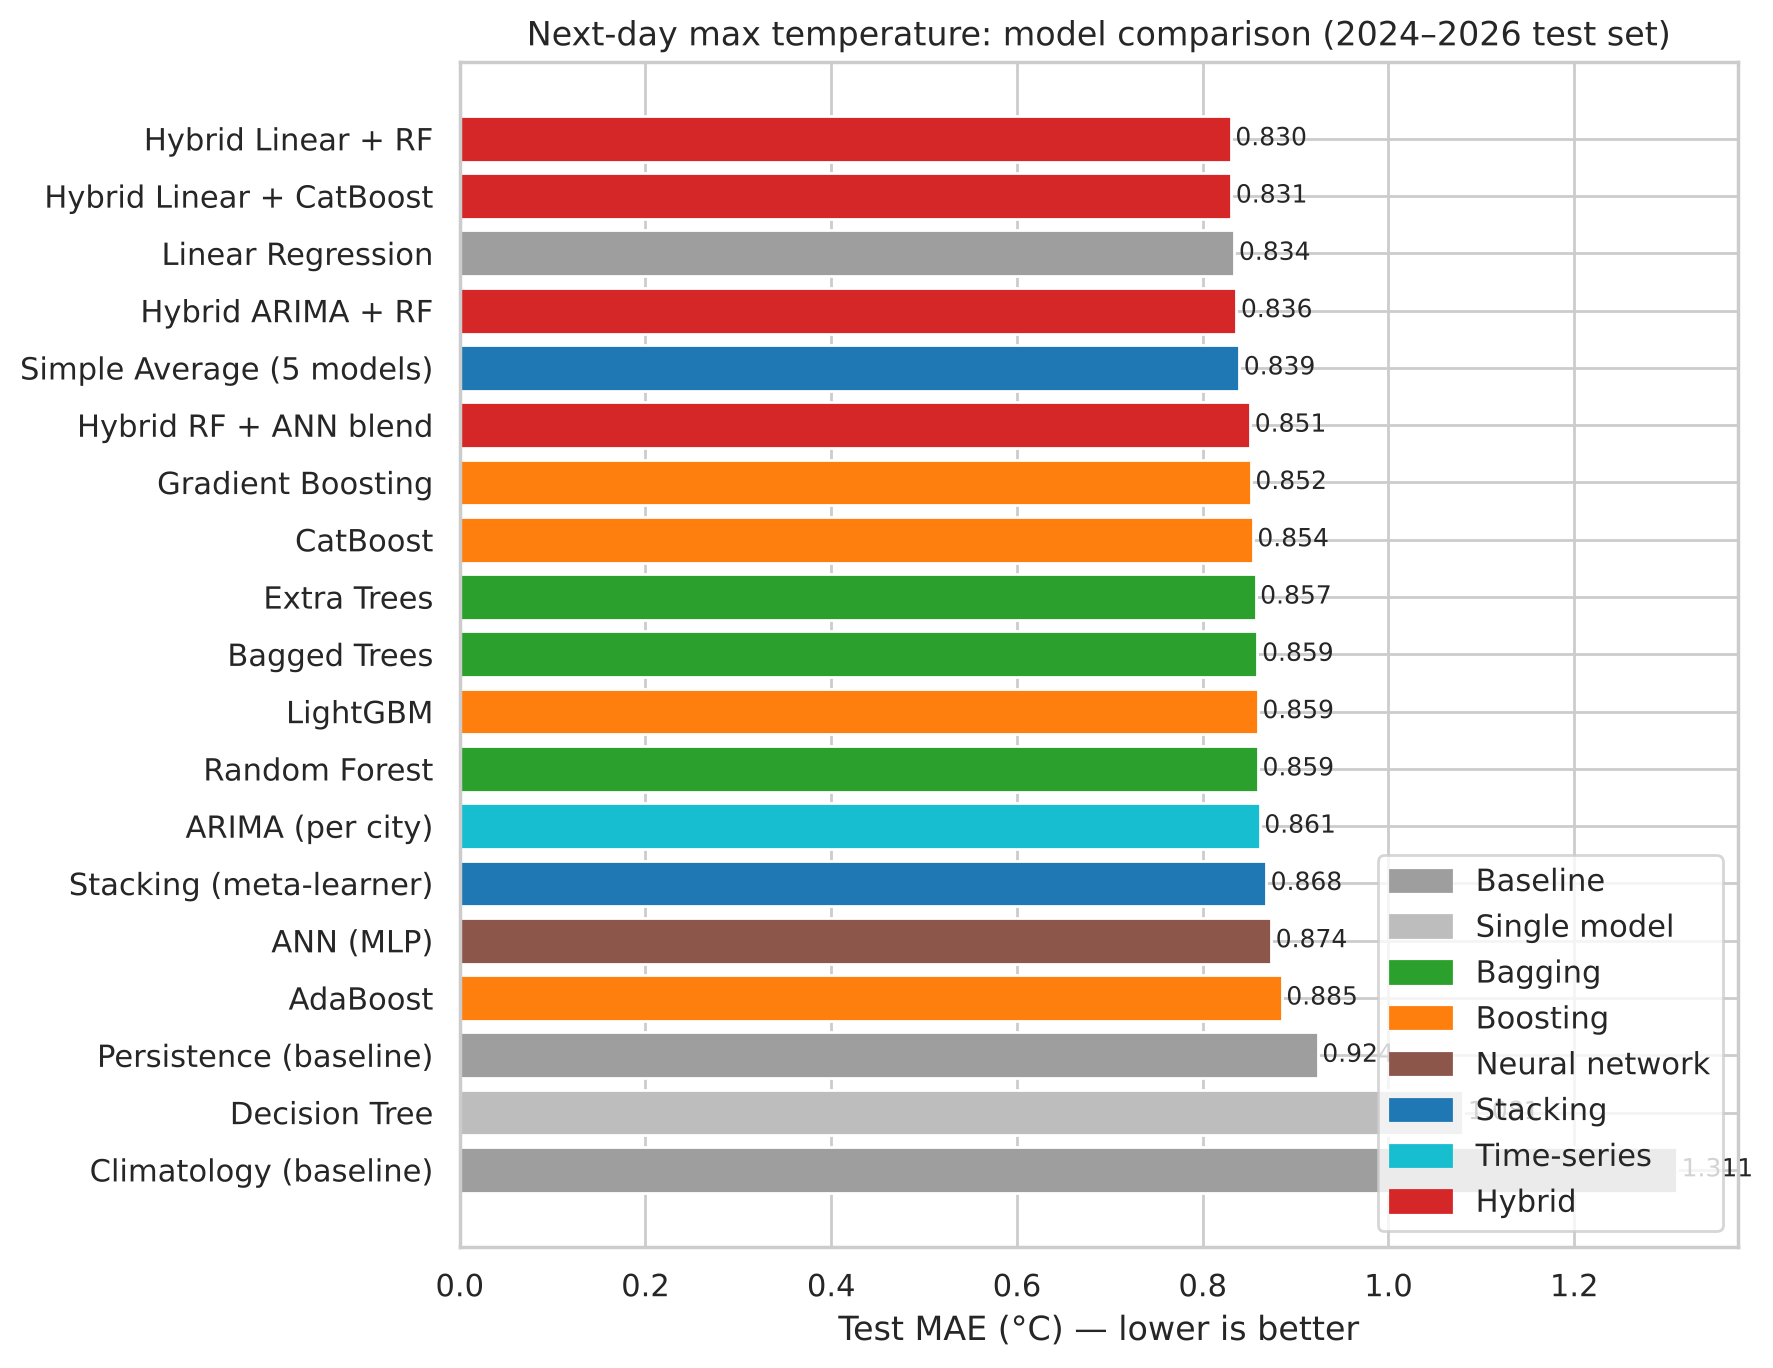

In [19]:
FAM_COLORS = {'Baseline':'#9e9e9e','Single model':'#bdbdbd','Bagging':'#2ca02c','Boosting':'#ff7f0e',
              'Neural network':'#8c564b','Stacking':'#1f77b4','Time-series':'#17becf','Hybrid':'#d62728'}
r = res.sort_values('MAE', ascending=False)
plt.figure(figsize=(9, 7))
plt.barh(r.index, r.MAE, color=[FAM_COLORS[f] for f in r.family])
for i, v in enumerate(r.MAE): plt.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color=c, label=f) for f, c in FAM_COLORS.items()], loc='lower right')
plt.xlabel('Test MAE (°C) — lower is better'); plt.title('Next-day max temperature: model comparison (2024–2026 test set)')
plt.tight_layout(); plt.show()

In [20]:
# Per-city performance of key models
key = ['Persistence (baseline)', 'Linear Regression', 'Decision Tree', 'Random Forest', 'LightGBM', 'CatBoost', 'ANN (MLP)',
       'Stacking (meta-learner)', 'Hybrid ARIMA + RF', 'Hybrid RF + ANN blend', 'Hybrid Linear + RF']
key = list(dict.fromkeys(key + [res.index[0]]))
per_city = pd.DataFrame({m: test.assign(p=PREDS[m]).groupby('city').apply(lambda g: mean_absolute_error(g.target, g.p)) for m in key}).T
per_city.style.format('{:.3f}').background_gradient(axis=0, cmap='RdYlGn_r')

city,Colombo,Kandy,Nuwara Eliya
Persistence (baseline),0.802,0.998,0.972
Linear Regression,0.712,0.908,0.882
Decision Tree,0.928,1.193,1.120
Random Forest,0.742,0.938,0.899
LightGBM,0.745,0.949,0.884
CatBoost,0.736,0.945,0.881
ANN (MLP),0.745,0.947,0.929
Stacking (meta-learner),0.727,0.930,0.948
Hybrid ARIMA + RF,0.725,0.914,0.870
Hybrid RF + ANN blend,0.730,0.928,0.895


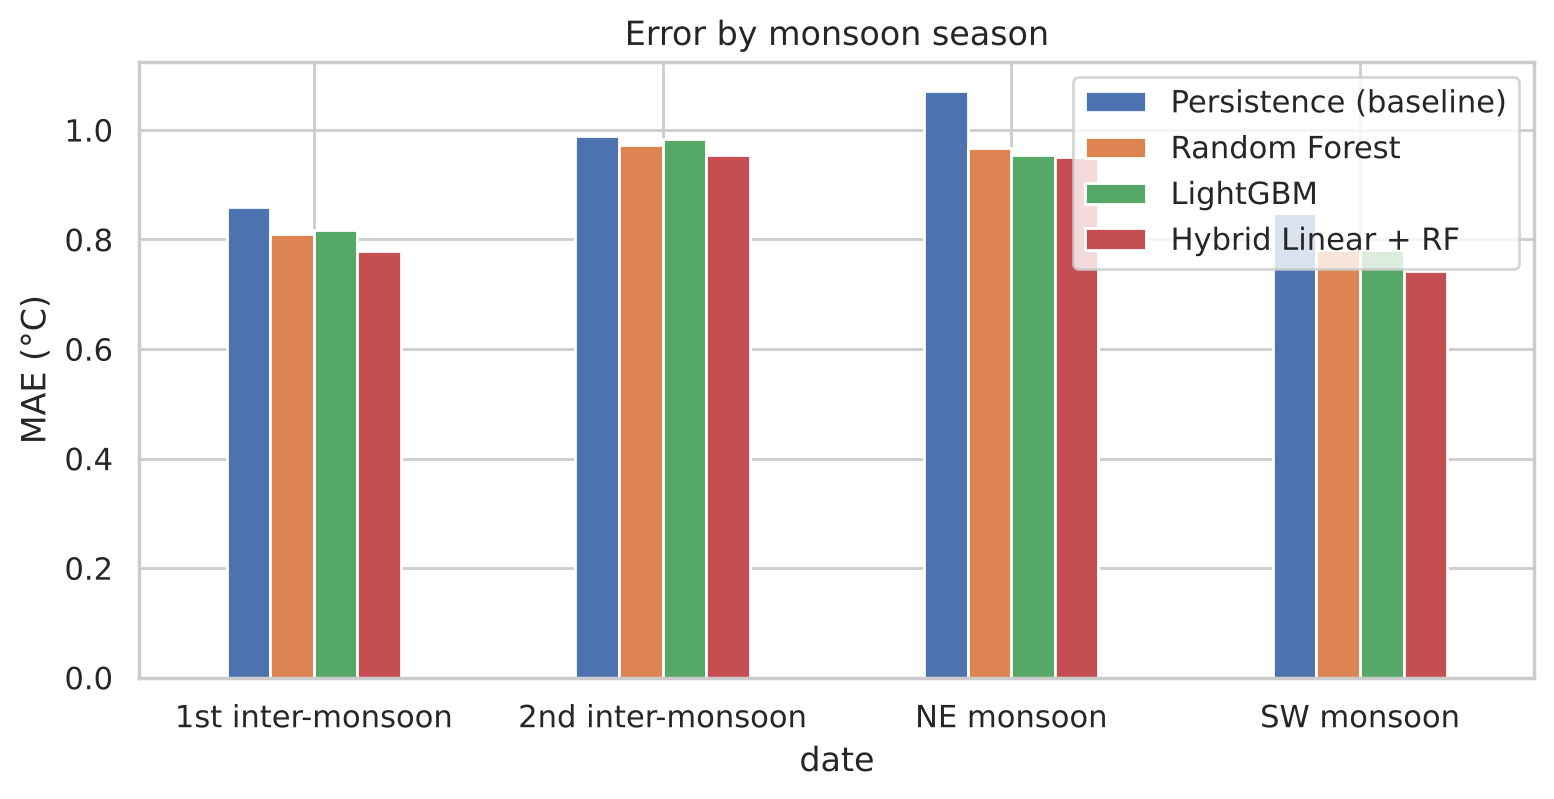

,Persistence (baseline),Random Forest,LightGBM,Hybrid Linear + RF
date,,,,
1st inter-monsoon,0.860,0.810,0.818,0.779
2nd inter-monsoon,0.990,0.972,0.983,0.955
NE monsoon,1.071,0.968,0.955,0.950
SW monsoon,0.848,0.781,0.781,0.742


In [21]:
# Error by monsoon season (best ensemble vs persistence)
best = res.index[0]
season = test.date.dt.month.map(monsoon)
by_season = pd.DataFrame({m: (np.abs(yte - PREDS[m])).groupby(season).mean() for m in ['Persistence (baseline)', 'Random Forest', 'LightGBM', best]})
by_season = by_season.loc[:, ~by_season.columns.duplicated()]
by_season.plot(kind='bar', figsize=(9, 4), rot=0); plt.ylabel('MAE (°C)'); plt.title('Error by monsoon season'); plt.show()
by_season.round(3)

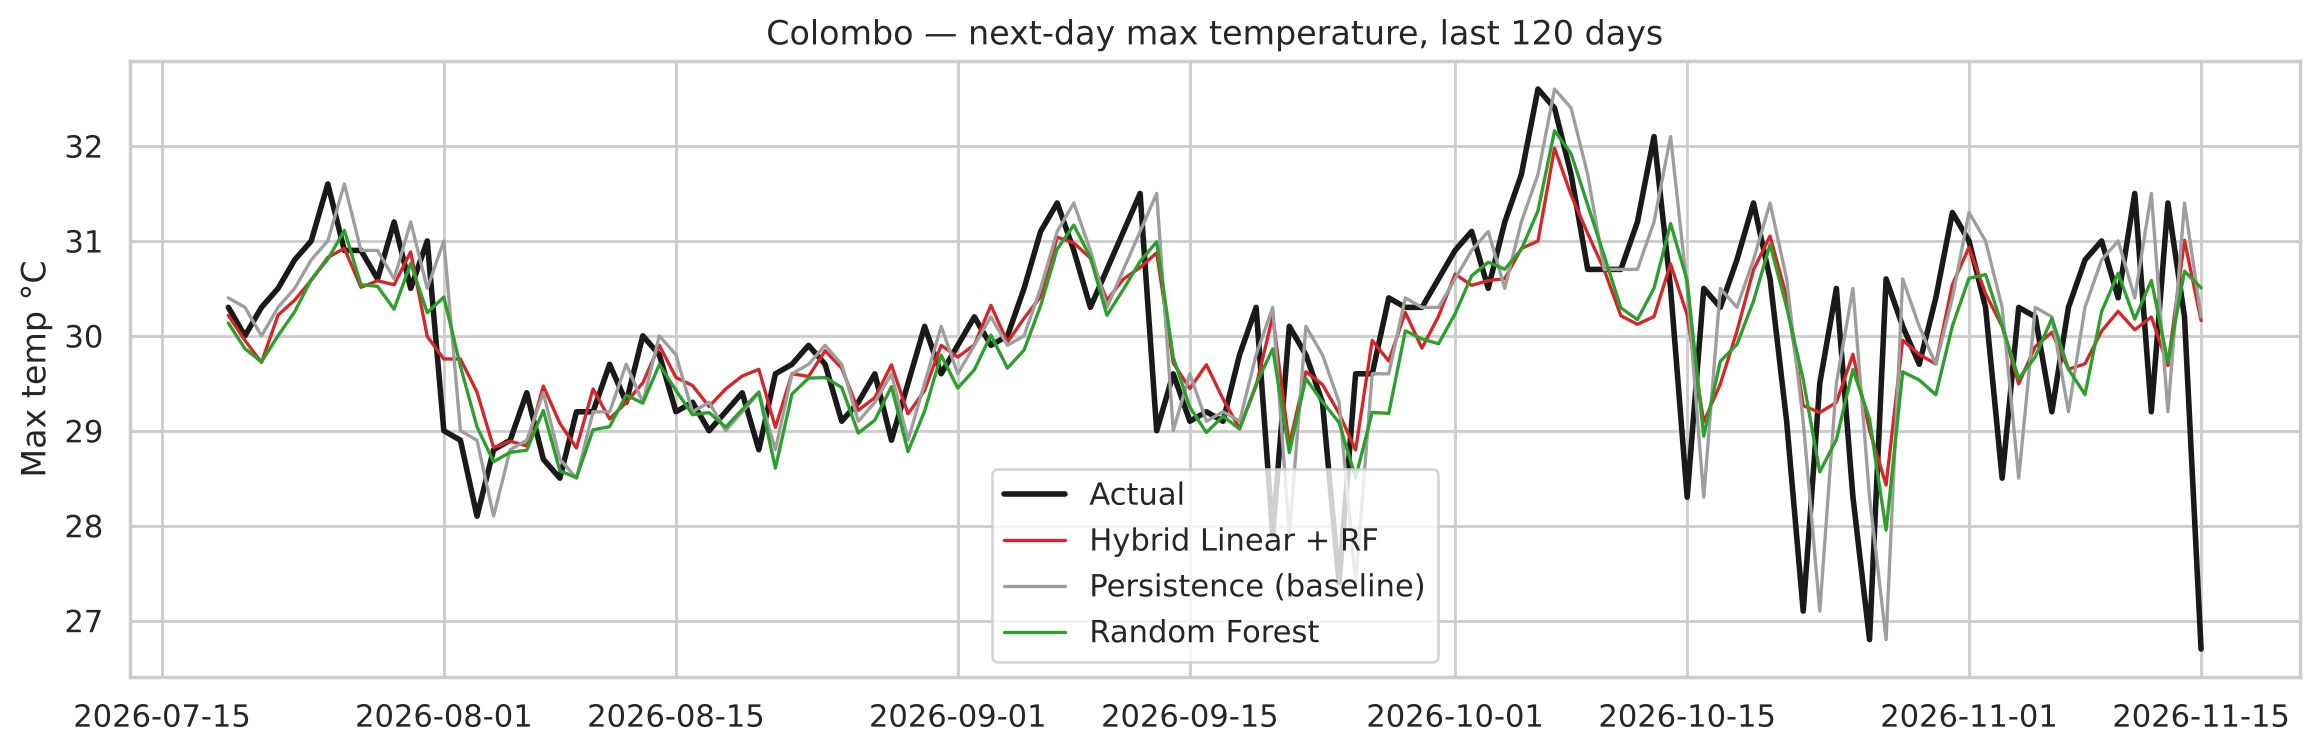

In [22]:
# Actual vs predicted — Colombo, last 120 days of test set
c = test.city == 'Colombo'
d = test[c].date + pd.Timedelta(days=1)
plt.figure(figsize=(14, 4))
plt.plot(d.values[-120:], yte[c].values[-120:], 'k-', lw=2, label='Actual')
for m, col in [(best, '#d62728'), ('Persistence (baseline)', '#9e9e9e'), ('Random Forest', '#2ca02c')]:
    plt.plot(d.values[-120:], PREDS[m][c.values][-120:], lw=1.2, label=m, color=col)
plt.legend(); plt.ylabel('Max temp °C'); plt.title('Colombo — next-day max temperature, last 120 days'); plt.show()

## 11. What drives the forecast? (feature importance)

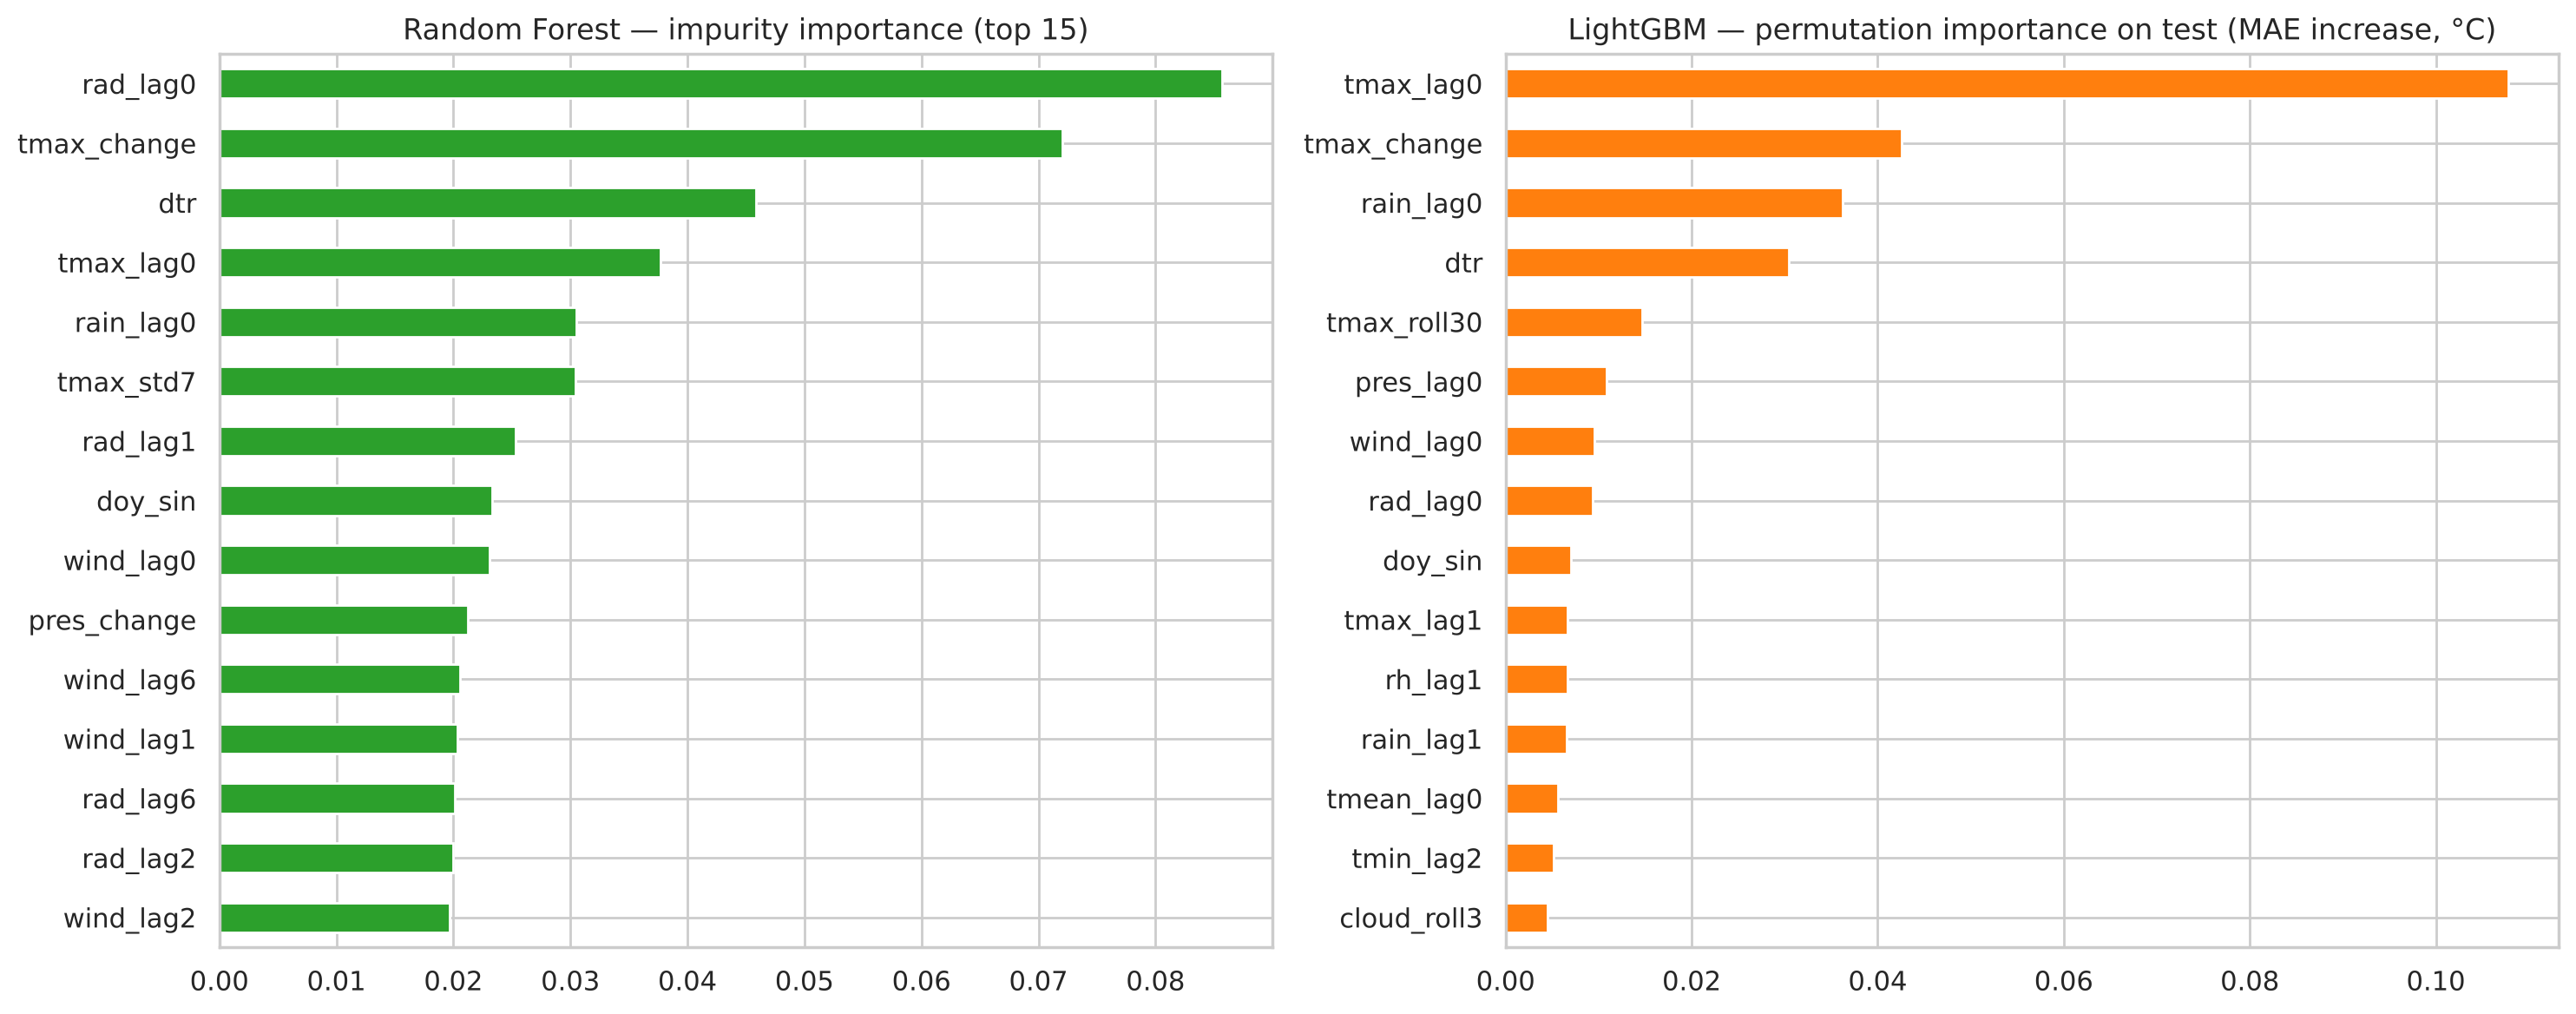

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp_rf = pd.Series(models['Random Forest'].feature_importances_, index=FEATURES).nlargest(15)
imp_rf[::-1].plot(kind='barh', ax=axes[0], color='#2ca02c'); axes[0].set_title('Random Forest — impurity importance (top 15)')
pi = permutation_importance(models['LightGBM'], Xte, yte - Xte['tmax_lag0'], n_repeats=5, random_state=SEED, scoring='neg_mean_absolute_error', n_jobs=-1)
imp_lgb = pd.Series(pi.importances_mean, index=FEATURES).nlargest(15)
imp_lgb[::-1].plot(kind='barh', ax=axes[1], color='#ff7f0e'); axes[1].set_title('LightGBM — permutation importance on test (MAE increase, °C)')
plt.tight_layout(); plt.show()

## 12. Interpretation — *why* did the models perform this way?

In [24]:
# Numbers referenced in the interpretation below (computed, not hard-coded)
def g(m, k='MAE'): return res.loc[m, k]
print(f"Best model           : {best}  (MAE {g(best):.3f} °C, R² {g(best,'R2'):.3f}, {res.loc[best,'Skill vs persistence (%)']:+.1f}% vs persistence)")
print(f"Persistence          : {g('Persistence (baseline)'):.3f} °C")
print(f"Single decision tree : {g('Decision Tree'):.3f} °C  → Bagged trees {g('Bagged Trees'):.3f}, RF {g('Random Forest'):.3f}")
print(f"Boosting             : LightGBM {g('LightGBM'):.3f}, CatBoost {g('CatBoost'):.3f}, GBM {g('Gradient Boosting'):.3f}, AdaBoost {g('AdaBoost'):.3f}")
print(f"ANN                  : {g('ANN (MLP)'):.3f};  Linear regression {g('Linear Regression'):.3f}")
print(f"Stacking             : {g('Stacking (meta-learner)'):.3f}; simple average {g('Simple Average (5 models)'):.3f}")
print(f"Linear hybrids       : Linear+RF {g('Hybrid Linear + RF'):.3f}, Linear+CatBoost {g('Hybrid Linear + CatBoost'):.3f}")
print(f"Hybrids              : ARIMA {g('ARIMA (per city)'):.3f} → ARIMA+RF {g('Hybrid ARIMA + RF'):.3f};  RF+ANN blend {g('Hybrid RF + ANN blend'):.3f} (w_RF={W_RF:.2f})")
print('Per-city MAE of best model:', per_city.loc[best].round(3).to_dict())

Best model           : Hybrid Linear + RF  (MAE 0.830 °C, R² 0.948, +10.1% vs persistence)
Persistence          : 0.924 °C
Single decision tree : 1.081 °C  → Bagged trees 0.859, RF 0.859
Boosting             : LightGBM 0.859, CatBoost 0.854, GBM 0.852, AdaBoost 0.885
ANN                  : 0.874;  Linear regression 0.834
Stacking             : 0.868; simple average 0.839
Linear hybrids       : Linear+RF 0.830, Linear+CatBoost 0.831
Hybrids              : ARIMA 0.861 → ARIMA+RF 0.836;  RF+ANN blend 0.851 (w_RF=0.65)
Per-city MAE of best model: {'Colombo': 0.706, 'Kandy': 0.908, 'Nuwara Eliya': 0.877}


### Key findings (test period 2024-01-01 → 2026-11-14, 3,147 forecasts)

| Rank | Model | Family | MAE (°C) | Skill vs persistence |
|---|---|---|---|---|
| 1 | **Hybrid Linear + Random Forest** | Hybrid | **0.830** | **+10.1 %** |
| 2 | Hybrid Linear + CatBoost | Hybrid | 0.831 | +10.1 % |
| 3 | Linear Regression | Baseline | 0.834 | +9.7 % |
| 4 | Hybrid ARIMA + RF | Hybrid | 0.836 | +9.5 % |
| 5 | Simple average of 5 models | Stacking | 0.839 | +9.2 % |
| … | Gradient Boosting / CatBoost / Extra Trees / RF / LightGBM | Boost / Bag | 0.852 – 0.859 | +7.0 – 7.8 % |
| … | Persistence ("tomorrow = today") | Baseline | 0.924 | 0 % |
| … | Single Decision Tree | Single | 1.081 | −17 % |

**1. Bagging cures the decision tree's variance.** One deep tree scored 1.08 °C, *worse than persistence*, because it
memorised noise in the training years. Averaging bootstrapped trees (Bagged Trees / Random Forest / Extra Trees) cut the
error by **~20 % to 0.86 °C**. The "bagging in action" curve shows the error falling quickly over the first ~25 trees
and then flattening: once the trees' errors are averaged out, only the shared, irreducible error is left.

**2. Boosting edges out bagging, but only a little.** Gradient Boosting (0.852) and CatBoost (0.854) beat Random Forest
(0.859), because boosting reduces *bias*: it fits the remaining errors step by step. CatBoost's ordered boosting and
symmetric trees made it the most robust boosted model with almost no tuning, and it trained ~3× faster than RF.
AdaBoost was the weakest ensemble (0.885): re-weighting "hard" days makes it chase random, unforecastable temperature
spikes, which is bad for a noisy target.

**3. Why does plain linear regression do so well?** Next-day temperature in tropical Sri Lanka is mostly a **smooth,
nearly linear** problem: tomorrow ≈ today + a small correction from cloud, rain, humidity and season. Linear models
capture that exactly and **can extrapolate**. The test years were also the **hottest in the record** (Colombo's mean
daily max was 30.65 °C in 2026 vs 29.1–29.8 °C in 2017–2023; only the 2016 El Niño year came close), outside the range the trees saw in training. Trees cannot
predict values beyond their training range. To fix this, every model predicts the **change from today** instead of the
temperature itself. That kept the tree ensembles competitive, but linear regression still has the advantage on a mostly
linear signal.

**4. Hybrids win by combining strengths.** The best model lets **linear regression handle the linear signal** and has a
**Random Forest learn the non-linear residuals**, such as interactions between heavy rain and thick cloud. It has the lowest
error overall and in Colombo, ties Linear Regression in Kandy, and is close to the best in Nuwara Eliya. The **ARIMA + RF** hybrid follows the same idea with ARIMA as
the linear part, and it improved ARIMA from 0.861 to 0.836 °C. The **RF + ANN** blend (65 % RF) beat both of its members
(0.851 vs 0.859 / 0.874) because the forest's step-like errors and the network's smooth errors partly cancel.

**5. Stacking: the "forecast-combination puzzle".** The learned stacker (0.868) did *worse* than a simple average of the
same five models (0.839). Its meta-learner gave all its weight to Linear Regression and RF and dropped LightGBM, CatBoost
and the ANN, because those base predictions are >99.6 % correlated (the boosted models' predicted *changes* correlate
0.94–0.96 with RF's) and the out-of-fold meta-features come from models
trained on less history than the final ones. When base learners are this similar and the data are non-stationary (a
warming trend), learned weights overfit and equal weights are more robust. This is a well-known result in forecasting
(Stock & Watson 2004; Smith & Wallis 2009).

**6. Geography and seasons.** Colombo is the easiest city to forecast (best MAE 0.71 °C): the sea moderates its weather.
**Kandy (0.91 °C)** and **Nuwara Eliya (0.88 °C)** are harder because hill-country convection and orographic cloud cause
sharper day-to-day swings. The ensembles helped most in the **North-East monsoon** (−11 % error vs persistence) and the
**SW monsoon** (−12 %), when cloud and rain regimes, which the trees model as non-linear thresholds, decide whether the
afternoon heats up.

**7. What the models look at.** Both importance methods agree: today's max temperature and its recent change, the
**diurnal temperature range** (a proxy for clear vs cloudy skies), **today's solar radiation** and **today's rainfall**
are the top drivers. Season (`doy_sin`) and pressure changes (approaching weather systems) come next. This matches how
meteorologists reason about tomorrow's temperature.

**Bottom line:** on this problem ensembles turn a poor single tree into a forecaster ~10 % better than persistence.
The best results come from **hybridising** ensembles with a model that suits the structure of the data, rather than
from adding more trees.

## 13. Export artefacts for the Streamlit dashboard

In [25]:
res.to_csv('artifacts/leaderboard.csv')
per_city.to_csv('artifacts/per_city_mae.csv')
by_season.to_csv('artifacts/season_mae.csv')
pred_df = test[['city', 'date', 'target', 'tmax_lag0']].copy()
pred_df['forecast_for'] = pred_df.date + pd.Timedelta(days=1)
for m, p in PREDS.items(): pred_df[m] = p
pred_df.to_csv('artifacts/test_predictions.csv', index=False)
test[['city', 'date'] + FEATURES].to_csv('artifacts/test_features.csv.gz', index=False)
df.to_csv('artifacts/weather_daily.csv.gz', index=False)
pd.DataFrame({'Random Forest': imp_rf, 'LightGBM (perm.)': imp_lgb}).to_csv('artifacts/feature_importance.csv')
pd.DataFrame({'k': ks, 'mae': curve}).to_csv('artifacts/bagging_curve.csv', index=False)
json.dump({'stack_weights': weights.to_dict(), 'stack_intercept': float(meta.intercept_), 'w_rf': float(W_RF),
           'features': FEATURES, 'target_mode': 'delta_from_tmax_lag0', 'split': str(SPLIT.date()), 'best': best,
           'n_train': int(len(train)), 'n_test': int(len(test))}, open('artifacts/meta.json', 'w'), indent=2)
# Light-weight models for the dashboard's "what-if" predictor
joblib.dump({'Random Forest': RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.4, n_jobs=-1, random_state=SEED).fit(Xtr, ytr_d),
             'Linear Regression': models['Linear Regression'], 'LightGBM': models['LightGBM'], 'CatBoost': models['CatBoost'], 'ANN (MLP)': models['ANN (MLP)'],
             'meta': meta, 'Linear+RF residual': models['Hybrid Linear + RF (residual)']}, 'artifacts/models.joblib', compress=3)
print(sorted(os.listdir('artifacts')))

['bagging_curve.csv', 'feature_importance.csv', 'leaderboard.csv', 'meta.json', 'models.joblib', 'per_city_mae.csv', 'season_mae.csv', 'test_features.csv.gz', 'test_predictions.csv', 'weather_daily.csv.gz']


## 14. Conclusion
* Ensembles turn a weak, high-variance decision tree (1.08 °C) into a reliable forecaster (~0.85 °C), and every ensemble
  beats the persistence and climatology baselines. Boosting (Gradient Boosting, CatBoost) slightly outperforms bagging.
* The **best model is a hybrid**: Linear Regression for the smooth, extrapolating signal + Random Forest for the non-linear
  residuals (MAE **0.830 °C**, +10 % skill vs persistence). Simple averaging beat learned stacking, a textbook
  "forecast-combination puzzle".
* Forecasting is hardest in the **hill country (Kandy, Nuwara Eliya)** and during the **NE monsoon**, where cloud and rain
  regimes change quickly.
* **Limitations:** reanalysis (ERA5) data are gridded model output, not raw station observations; only three locations;
  no numerical-weather-prediction inputs (which real forecasters use). **Next steps:** add more Department of Meteorology stations,
  multi-day horizons, quantile/uncertainty forecasts, and a heat-index classification head.

*Data: Weather data by Open-Meteo.com (CC BY 4.0), ERA5 reanalysis (Copernicus Climate Change Service).*
*GenAI disclosure: code and dashboard UI generated with assistance from Claude (Anthropic); reviewed and run by the author.*